# 09 · Cost and latency

What each system costs per question and how long it takes, from the saved results (no model calls). Costs are the model tokens priced from `config/pricing.yaml`
(OpenRouter's published rates) plus the re-ranker's per-search fee. Targets set before measuring: p50 8 s, p95 20 s.

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from policy_agent.ingest.paths import ROOT

R = ROOT / "eval" / "results"
pd.set_option("display.width", 170)
systems = {
    "B0 BM25 only (no LLM)": "B0_dev",
    "E6 chain, Haiku": "E6_dev",
    "E5 chain, Sonnet": "E5_dev",
    "E7 router agent": "E7_dev",
    "E8 final agent": "E8_dev",
    "E6T chain (held-out)": "E6T_test",
    "E7T router agent (held-out)": "E7T_test",
    "E8T final agent (held-out)": "E8T_test",
}
rows = {}
for name, f in systems.items():
    d = json.loads((R / f"{f}.json").read_text())
    rows[name] = {
        "runs": d["n_runs"],
        "cost per run $": d["cost_usd"]["mean_per_run"],
        "p50 s": d["latency_ms"]["p50"] / 1000,
        "p95 s": d["latency_ms"]["p95"] / 1000,
    }
table = pd.DataFrame(rows).T
display(table.round({"cost per run $": 4, "p50 s": 1, "p95 s": 1}))

,runs,cost per run $,p50 s,p95 s
B0 BM25 only (no LLM),21.0,0.0000,0.0,0.2
"E6 chain, Haiku",63.0,0.0013,6.0,25.0
"E5 chain, Sonnet",63.0,0.0294,9.9,26.9
E7 router agent,63.0,0.0024,12.8,30.0
E8 final agent,63.0,0.0024,10.5,17.7
E6T chain (held-out),45.0,0.0018,7.0,24.5
E7T router agent (held-out),45.0,0.0025,10.3,27.1
E8T final agent (held-out),45.0,0.0025,10.0,24.4


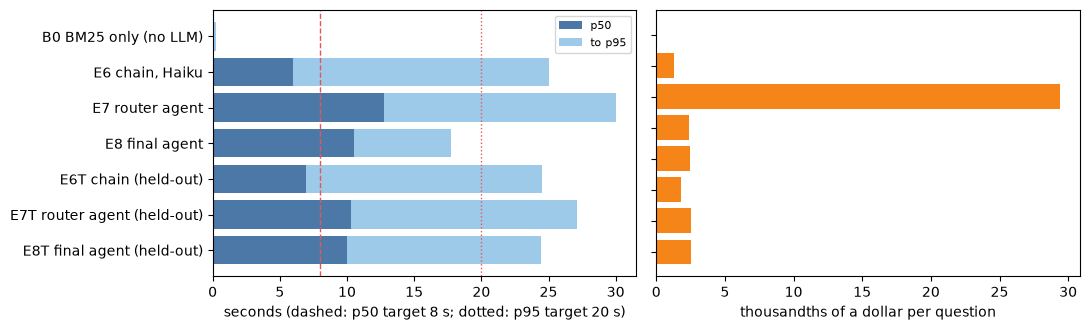

Sonnet costs 23 times Haiku per question (E5 is omitted from the latency chart; it is in the table above).


In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
t = table.drop("E5 chain, Sonnet")
ax[0].barh(t.index, t["p50 s"], color="#4C78A8", label="p50")
ax[0].barh(t.index, t["p95 s"] - t["p50 s"], left=t["p50 s"], color="#9ecae9", label="to p95")
ax[0].axvline(8, color="#E45756", linestyle="--", lw=1)
ax[0].axvline(20, color="#E45756", linestyle=":", lw=1)
ax[0].invert_yaxis()
ax[0].set_xlabel("seconds (dashed: p50 target 8 s; dotted: p95 target 20 s)")
ax[0].legend(fontsize=8)
ax[1].barh(table.index, table["cost per run $"] * 1000, color="#F58518")
ax[1].invert_yaxis()
ax[1].set_xlabel("thousandths of a dollar per question")
ax[1].set_yticklabels([])
plt.tight_layout()
plt.show()
sonnet, haiku = table.loc["E5 chain, Sonnet", "cost per run $"], table.loc["E6 chain, Haiku", "cost per run $"]
print(
    f"Sonnet costs {sonnet / haiku:.0f} times Haiku per question (E5 is omitted from the latency chart; it is in the table above)."
)

## Where the time goes
The agent makes two or three sequential model calls (choose tools, maybe a second round, write the answer), and the dense query embedding and re-ranker are network calls. Per-tool timings are in each run's log.

In [3]:
d = json.loads((R / "E8T_test.json").read_text())
tool_ms = {}
for r in d["runs"]:
    for line in r["output"]["agent"]["log"]:
        if line.startswith("act:"):
            for tool, ms in __import__("re").findall(r"(\w+)\[ok,(\d+)ms\]", line):
                tool_ms.setdefault(tool, []).append(int(ms))
display(
    pd.DataFrame({k: pd.Series(v).describe()[["count", "50%", "max"]] for k, v in tool_ms.items()}).T.rename(
        columns={"50%": "median ms", "max": "max ms"}
    )
)
runs = pd.DataFrame([{"calls": r["output"]["agent"]["llm_calls"], "s": r["latency_ms"] / 1000} for r in d["runs"]])
display(
    runs.groupby("calls")
    .s.agg(["count", "median", "max"])
    .round(1)
    .rename(columns={"count": "runs", "median": "median s", "max": "max s"})
)
print(
    "A run with 3 model calls costs about one more model round trip than a run with 2; the tools themselves are fast (milliseconds) apart from an occasional slow search (up to a few seconds, when it must embed the question and re-rank)."
)

,count,median ms,max ms
query_statistic,40.0,22.5,336.0
search_corpus,43.0,23.0,2781.0
compute_change,15.0,10.0,14.0
read_stats_resource,4.0,17.0,22.0


,runs,median s,max s
calls,,,
0,3,0.0,0.0
2,28,7.6,16.0
3,8,16.3,23.9
4,4,20.7,41.2
5,2,36.9,49.4


A run with 3 model calls costs about one more model round trip than a run with 2; the tools themselves are fast (milliseconds) apart from an occasional slow search (up to a few seconds, when it must embed the question and re-rank).


## Reading this

- The final agent is **cheaper and faster than the router agent**, which paid for a model call just to route (p95 about 27 s down to 24 s held-out, 30 s to 18 s on dev).
- A plain chain is quicker at the median but fails more cases that need tools; both are far cheaper than Sonnet.
- Neither agent meets the 8 s / 20 s latency targets. The levers in `docs/INNOVATION.md` are to run independent searches in parallel and to use a single `act` round for plain lookups.